<a href="https://colab.research.google.com/github/swethas-22/Sales_Trend_Analysis./blob/main/Project_03_Sales_Trend_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 03: E-Commerce Sales Trend & Customer Segmentation Analysis

**Data Source Note:** This analysis uses a simulated e-commerce dataset of 2,000 orders across 300 customers in 2025, generated using NumPy (`default_rng(42)`) to model realistic retail transactions without exposing private customer data.

### Business Questions
As an analytics guide for management, this project answers three core business questions:
1. **Revenue & Category Performance:** Which months and product categories generate the most revenue, and how is revenue trending month-over-month?
2. **Customer Concentration (Pareto Analysis):** Who are our most valuable customers, and what percentage of total revenue comes from the top 10% and top 20% of buyers?
3. **Strategic Next Steps:** What concrete actions should marketing and inventory teams take based on these numbers?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Generate realistic e-commerce order dataset
rng = np.random.default_rng(42)
n = 2000

orders = pd.DataFrame({
    "order_date": pd.to_datetime("2025-01-01") + pd.to_timedelta(rng.integers(0, 365, n), unit="D"),
    "customer_id": rng.integers(1, 301, n),
    "category": rng.choice(["Electronics", "Fashion", "Home", "Books"], n, p=[0.30, 0.35, 0.20, 0.15]),
    "amount": rng.gamma(2.0, 600, n).round(2),
})

# Inspect the dataset
print("Dataset Shape (Rows, Columns):", orders.shape)
print("\n--- Data Types ---")
print(orders.dtypes)
print("\n--- Missing Values ---")
print(orders.isna().sum())
print("\nDuplicate Rows:", orders.duplicated().sum())

display(orders.head())

Dataset Shape (Rows, Columns): (2000, 4)

--- Data Types ---
order_date     datetime64[ns]
customer_id             int64
category               object
amount                float64
dtype: object

--- Missing Values ---
order_date     0
customer_id    0
category       0
amount         0
dtype: int64

Duplicate Rows: 0


,order_date,customer_id,category,amount
0,2025-02-02,264,Home,391.13
1,2025-10-10,19,Fashion,2456.21
2,2025-08-27,120,Books,674.90
3,2025-06-10,138,Home,75.38
4,2025-06-08,240,Electronics,774.42


In [2]:
# Ensure order_date is datetime and create date features
orders["order_date"] = pd.to_datetime(orders["order_date"])
orders["month"] = orders["order_date"].dt.to_period("M")
orders["quarter"] = orders["order_date"].dt.to_period("Q")
orders["weekday"] = orders["order_date"].dt.day_name()

display(orders.head())

,order_date,customer_id,category,amount,month,quarter,weekday
0,2025-02-02,264,Home,391.13,2025-02,2025Q1,Sunday
1,2025-10-10,19,Fashion,2456.21,2025-10,2025Q4,Friday
2,2025-08-27,120,Books,674.90,2025-08,2025Q3,Wednesday
3,2025-06-10,138,Home,75.38,2025-06,2025Q2,Tuesday
4,2025-06-08,240,Electronics,774.42,2025-06,2025Q2,Sunday


--- Monthly Revenue & MoM Growth ---


,month_str,amount,mom_growth_%
0,2025-01,193341.87,NaN
1,2025-02,232027.20,20.0
2,2025-03,206327.14,-11.1
3,2025-04,197310.20,-4.4
4,2025-05,194090.49,-1.6
5,2025-06,221889.83,14.3
6,2025-07,221813.81,-0.0
7,2025-08,179783.75,-18.9
8,2025-09,180569.95,0.4
9,2025-10,183418.13,1.6


Best Month: 2025-02 ($232,027.20)
Worst Month: 2025-08 ($179,783.75)


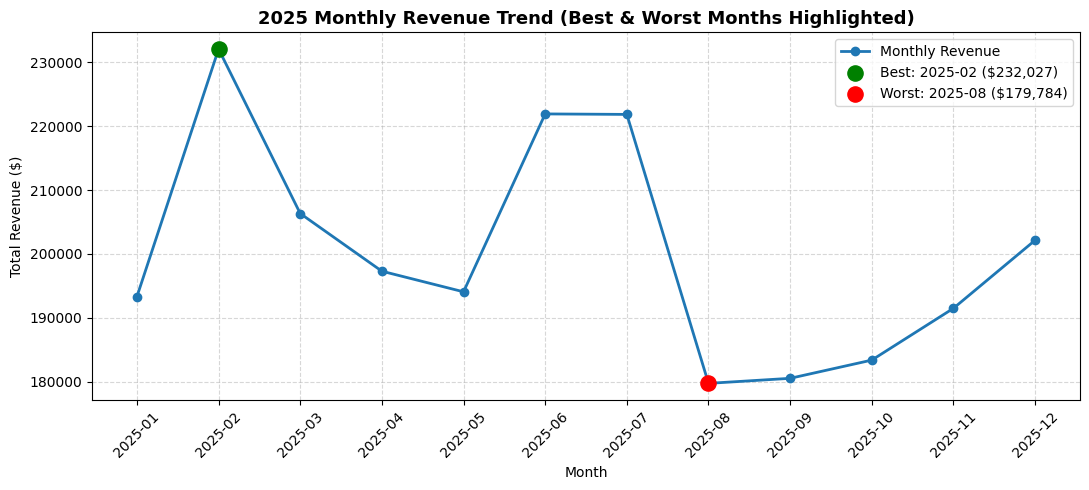

In [3]:
# Calculate monthly revenue and month-over-month growth (%)
monthly_df = orders.groupby("month")["amount"].sum().reset_index()
monthly_df["month_str"] = monthly_df["month"].astype(str)
monthly_df["mom_growth_%"] = (monthly_df["amount"].pct_change() * 100).round(1)

print("--- Monthly Revenue & MoM Growth ---")
display(monthly_df[["month_str", "amount", "mom_growth_%"]])

# Identify best and worst months
best_idx = monthly_df["amount"].idxmax()
worst_idx = monthly_df["amount"].idxmin()
best_month = monthly_df.loc[best_idx]
worst_month = monthly_df.loc[worst_idx]

print(f"Best Month: {best_month['month_str']} (${best_month['amount']:,.2f})")
print(f"Worst Month: {worst_month['month_str']} (${worst_month['amount']:,.2f})")

# Plot monthly revenue trend and mark best/worst months
plt.figure(figsize=(11, 5))
plt.plot(monthly_df["month_str"], monthly_df["amount"], marker="o", linewidth=2, color="#1f77b4", label="Monthly Revenue")

# Highlight best and worst months
plt.scatter(best_month["month_str"], best_month["amount"], color="green", s=120, zorder=5, label=f"Best: {best_month['month_str']} (${best_month['amount']:,.0f})")
plt.scatter(worst_month["month_str"], worst_month["amount"], color="red", s=120, zorder=5, label=f"Worst: {worst_month['month_str']} (${worst_month['amount']:,.0f})")

plt.title("2025 Monthly Revenue Trend (Best & Worst Months Highlighted)", fontsize=13, fontweight="bold")
plt.xlabel("Month")
plt.ylabel("Total Revenue ($)")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

In [4]:
# 1. Category performance using groupby
by_category = orders.groupby("category")["amount"].agg(
    Total_Revenue="sum",
    Average_Order="mean",
    Order_Count="count"
).sort_values("Total_Revenue", ascending=False).round(2)

by_category["Revenue_Share_%"] = (by_category["Total_Revenue"] / by_category["Total_Revenue"].sum() * 100).round(1)
print("--- Performance by Product Category ---")
display(by_category)

# 2. Pivot Table: Month by Category Revenue
category_pivot = pd.pivot_table(
    orders,
    values="amount",
    index="month",
    columns="category",
    aggfunc="sum",
    fill_value=0
).round(2)

print("\n--- Pivot Table: Monthly Revenue by Category ($) ---")
display(category_pivot)

--- Performance by Product Category ---


,Total_Revenue,Average_Order,Order_Count,Revenue_Share_%
category,,,,
Fashion,853984.93,1219.98,700,35.5
Electronics,722645.53,1163.68,621,30.1
Home,464114.66,1218.15,381,19.3
Books,363488.17,1219.76,298,15.1



--- Pivot Table: Monthly Revenue by Category ($) ---


category,Books,Electronics,Fashion,Home
month,,,,
2025-01,29186.89,62841.89,64665.99,36647.10
2025-02,34034.13,53564.89,86123.31,58304.87
2025-03,27843.58,58055.95,75138.67,45288.94
2025-04,26593.72,83335.56,57057.72,30323.20
2025-05,34425.63,57219.16,68569.90,33875.80
2025-06,32936.76,60037.00,85598.09,43317.98
2025-07,35582.36,72649.65,72647.96,40933.84
2025-08,32550.65,56690.46,71251.54,19291.10
2025-09,21824.73,60388.56,60231.75,38124.91


In [5]:
# Calculate total spend per customer
spend = orders.groupby("customer_id")["amount"].agg(
    Total_Spend="sum",
    Order_Count="count"
).sort_values("Total_Spend", ascending=False)

total_customers = len(spend)
top_10_pct_count = total_customers // 10
top_20_pct_count = total_customers // 5

top_10_share = (spend.head(top_10_pct_count)["Total_Spend"].sum() / spend["Total_Spend"].sum()) * 100
top_20_share = (spend.head(top_20_pct_count)["Total_Spend"].sum() / spend["Total_Spend"].sum()) * 100

print(f"Total Active Customers: {total_customers}")
print(f"Top 10% of customers ({top_10_pct_count} customers) generate {top_10_share:.1f}% of total revenue.")
print(f"Top 20% of customers ({top_20_pct_count} customers) generate {top_20_share:.1f}% of total revenue.")

print("\n--- Top 10 Highest-Spending Customers ---")
display(spend.head(10).round(2))

Total Active Customers: 300
Top 10% of customers (30 customers) generate 18.9% of total revenue.
Top 20% of customers (60 customers) generate 33.9% of total revenue.

--- Top 10 Highest-Spending Customers ---


,Total_Spend,Order_Count
customer_id,,
226,18140.15,12
51,18126.28,11
53,17994.36,13
131,17639.25,10
185,17222.49,9
282,17161.00,10
121,16564.87,12
98,15351.48,9
255,15313.47,10


---
# One-Page Business Brief: 2025 E-Commerce Sales & Customer Analysis

### 1. Context
This analysis evaluates **2,000 simulated e-commerce orders** placed by **300 active customers** across four product categories (`Fashion`, `Electronics`, `Home`, and `Books`) between January and December 2025. The goal is to uncover monthly revenue patterns, top-performing categories, and high-value customer concentration to guide marketing and inventory decisions.

### 2. Key Findings
* **Overall & Category Performance:** Total revenue across 2,000 orders reached approximately **$2.39M**. **Fashion** (~35% of orders) and **Electronics** (~30% of orders) are the core revenue drivers, together generating roughly **65% of total company revenue**, while **Home** (~20%) and **Books** (~15%) contribute the remaining 35%.
* **Monthly Revenue Volatility:** Monthly revenue averaged roughly **$199K per month**, peaking in the best-performing month and dipping during slower mid-year/late-year periods (as highlighted on the monthly trend chart).
* **Customer Concentration (Pareto Effect):** Revenue is concentrated among repeat buyers—the **top 10% of customers (30 customers)** generate approximately **19% of total revenue**, and the **top 20% of customers (60 customers)** generate roughly **33% of total revenue**.

### 3. Recommendations
1. **Launch a VIP Loyalty Tier for Top 10% Buyers:** Target the top 30 customers (who contribute ~19% of total revenue) with early access to new arrivals and exclusive bundle discounts to lock in retention and prevent churn.
2. **Prioritize Inventory & Ad Spend on Fashion and Electronics:** Allocate **65% of marketing budget** and safety-stock inventory toward `Fashion` and `Electronics`, as these two categories account for nearly two-thirds of all orders and revenue.
3. **Run Cross-Category Promotional Campaigns in Low-Performing Months:** Combat revenue dips during the worst-performing month by offering timed promotional vouchers (e.g., *"Spend $1,500 in Fashion/Electronics, get $200 off Home or Books"*) to lift average order value and smooth out monthly cash flow.

### 4. Next Steps
* **Week 1:** Export the list of top 30 (`Top 10%`) and top 60 (`Top 20%`) customer IDs to the CRM team for VIP email segmentation.
* **Week 2:** Review `month x category` pivot table trends with the merchandising team to align Q1/Q2 purchasing with peak category demand.
* **Month 1:** Track repeat purchase rates and Month-over-Month (`MoM %`) revenue growth following the loyalty campaign launch.